## Evaluation and validation of the effective borefield thermal resistance

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pygfunction3 as gt3
import pygfunction as gt

#### Borefield parameters
Field 5 series-connected boreholes of unequal lengths

In [2]:
# Borehole dimensions
L = np.array([75.0, 100.0, 125.0, 150.0, 75.0])
D = 4.          # Borehole buried depth (in meters)
r_b = 0.075     # Borehole radius (in meters)
# Positions (x, y) of the boreholes on the horizontal plane (in meters)
B = 7.5         # Borehole spacing (in meters)
n_boreholes = len(L)
p_head = np.stack((np.arange(np.max(n_boreholes)) * B, np.zeros(np.max(n_boreholes))), axis=1)
field = gt3.Borefield(L, D, r_b, p_head)
field_reversed = gt3.Borefield(L[::-1], D, r_b, p_head[::-1])
# Borehole connectivity (boreholes are connected in series)
borehole_connectivity=np.arange(-1, field.n_boreholes - 1)

# Pipe dimensions
# Pipe outer radius (m)
r_p_out = 0.02
# Pipe inner radius (m)
r_p_in = 0.015

# Pipe positions
# Shank spacing
shank = 0.05
# Single U-tube
p_pipe = [(-shank, 0.0), (shank, 0.0)]

# Pipe properties
k_p = 0.4           # Pipe thermal conductivity (W/m.K)
epsilon = 1e-6      # Pipe roughness (in meters)

# Ground properties
k_s = 2.0           # Ground thermal conductivity (W/m.K)
alpha = 1e-6    # Soil diffusivity [m^2/s]

# Grout properties
k_b = 1.0           # Grout thermal conductivity (W/m.K)

#### Parameters for the evaluation of g-functions

In [3]:
# Basis functions
n_nodes = 11
basis = gt3.Basis(n_nodes)

# Time array for g-function evaluation
t_s = np.mean(L)**2 / (9 * alpha)
tt_s = np.linspace(-10., 5., 25)
time = np.exp(tt_s) * t_s

#### Fluid Properties
The fluid is propylene-glycol (20%) and the internal thermal resistances were calculated for a typical borehole configuration using the multipole method.

In [4]:
# Fluid mass flow rate (in kg/s)
m_flow = np.array([0.25, 0.5])
T_nominal = 20.
x = 0.2
fluid = gt3.Fluid.from_scp(
    'PropyleneGlycol', T_nominal, x=x
)
cp_f = fluid.specific_heat()  # Fluid specific heat capacity (in J/kg.K)

### Network object

In [5]:
pipe = gt3.SingleUTube(p_pipe, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon, J=2)
network = gt3.Network(field, pipe, borehole_connectivity=borehole_connectivity)

pipe_reversed = gt3.SingleUTube(p_pipe[::-1], r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon, J=2)
network_reversed = gt3.Network(field_reversed, pipe_reversed, borehole_connectivity=borehole_connectivity)

#### g-function

In [6]:
g_funcs = []
q_bs = []
T_bs = []
for _m_flow in m_flow:
    g_func, q_b, T_b = gt3.g_function(
        network,
        time=time,
        alpha=alpha,
        k_s=k_s,
        basis=basis,
        m_flow=_m_flow,
        trf_backend='similarities',
        full_output=True,
        options={'rTol': 1e-2, 'sTol': 1e-2}
    )
    g_funcs.append(g_func)
    q_bs.append(q_b)
    T_bs.append(T_b)

g_funcs_reversed = []
q_bs_reversed = []
T_bs_reversed = []
for _m_flow in m_flow:
    g_func, q_b, T_b = gt3.g_function(
        network_reversed,
        time=time,
        alpha=alpha,
        k_s=k_s,
        basis=basis,
        m_flow=-_m_flow,
        trf_backend='similarities',
        full_output=True,
        options={'rTol': 1e-2, 'sTol': 1e-2}
    )
    g_funcs_reversed.append(g_func)
    q_bs_reversed.append(q_b)
    T_bs_reversed.append(T_b)

Evaluating thermal response factors... done (0.12 seconds)
Solving for g-function... done (0.01 seconds)
Total time: 0.14 seconds
Evaluating thermal response factors... done (0.12 seconds)
Solving for g-function... done (0.01 seconds)
Total time: 0.14 seconds
Evaluating thermal response factors... done (0.12 seconds)
Solving for g-function... done (0.01 seconds)
Total time: 0.13 seconds
Evaluating thermal response factors... done (0.12 seconds)
Solving for g-function... done (0.01 seconds)
Total time: 0.13 seconds


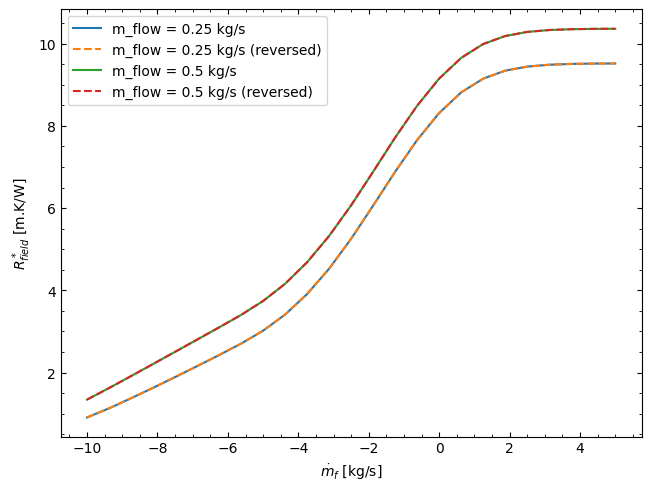

In [7]:
fig, ax = plt.subplots(constrained_layout=True)
ax = gt3.plot._format_axis(ax, [r'$\dot{m}_f$ [kg/s]', r'$R_{field}^*$ [m.K/W]'])
for _g_func, _g_func_reversed, _m_flow in zip(g_funcs, g_funcs_reversed, m_flow):
    ax.plot(tt_s, _g_func, label=f'm_flow = {_m_flow} kg/s')
    ax.plot(tt_s, _g_func_reversed, '--', label=f'm_flow = {_m_flow} kg/s (reversed)')
ax.legend()
plt.show()

#### Temperature and heat extraction rate profiles

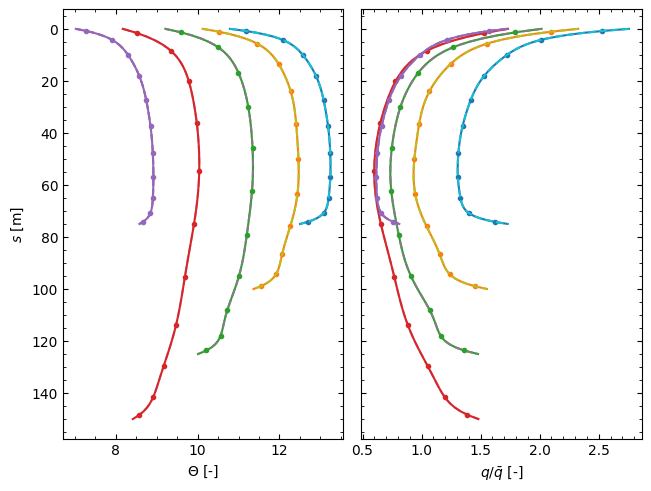

In [8]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Theta$ [-]', '$s$ [m]'], inverse_y=True)
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$q / \bar{q}$ [-]')
xi_eval = np.linspace(-1., 1., num=101)
s_eval = field.longitudinal_position(xi_eval)
s_eval_reversed = field_reversed.longitudinal_position(xi_eval)
psi = basis.basis_function(xi_eval)
T_b_eval = np.einsum('ij, kj -> ki', psi, T_bs[0][-1])
T_b_eval_reversed = np.einsum('ij, kj -> ki', psi, T_bs_reversed[0][-1])
q_b_eval = np.einsum('ij, kj -> ki', psi, q_bs[0][-1])
q_b_eval_reversed = np.einsum('ij, kj -> ki', psi, q_bs_reversed[0][-1])
s_nodes = field.longitudinal_position(basis.xi)
for i in range(field.n_boreholes):
    axs[0].plot(T_b_eval[i], s_eval[:, i], '-', color=f'C{i}')
    axs[0].plot(T_b_eval_reversed[i], s_eval_reversed[:, i], '--', color=f'C{i + field.n_boreholes}')
    axs[0].plot(T_bs[0][-1][i], s_nodes[:, i], '.', color=f'C{i}')
    axs[1].plot(q_b_eval[i], s_eval[:, i], '-', color=f'C{i}')
    axs[1].plot(q_b_eval_reversed[i], s_eval_reversed[:, i], '--', color=f'C{i + field.n_boreholes}')
    axs[1].plot(q_bs[0][-1][i], s_nodes[:, i], '.', color=f'C{i}')
plt.show()

### pygfunction v2

In [9]:
field_pygfunction = gt.borefield.Borefield(L, D, r_b, p_head[:, 0], p_head[:, 1])
bore_connectivity = [i - 1 for i in range(n_boreholes)]
options = {'nSegments': n_nodes,
           'disp': True,
           'profiles': True}
g_funcs_pygfunction = []
for _m_flow in m_flow:
    # Pipe thermal resistance
    R_p = gt.pipes.conduction_thermal_resistance_circular_pipe(
            r_p_in, r_p_out, k_p)
    # Fluid to inner pipe wall thermal resistance (Single U-tube)
    h_f = gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
            _m_flow, r_p_in, fluid.viscosity(), fluid.density(), fluid.conductivity(), fluid.specific_heat(), epsilon)
    R_f = 1.0 / (h_f * 2 * np.pi * r_p_in)

    # Single U-tube, same for all boreholes in the bore field
    UTubes = []
    for borehole in field_pygfunction:
        SingleUTube = gt.pipes.SingleUTube(
            p_pipe, r_p_in, r_p_out, borehole, k_s, k_b, R_f + R_p)
        UTubes.append(SingleUTube)
    network = gt.networks.Network(
        field_pygfunction,
        UTubes,
        bore_connectivity=bore_connectivity)

    # Effective bore field thermal resistance
    gfunc = gt.gfunction.gFunction(
        network, alpha, time=time, m_flow_network=_m_flow, cp_f=cp_f,
        boundary_condition='MIFT', options=options
        )
    g_funcs_pygfunction.append(gfunc)

d:\codes\pygfunction-HigherOrder\.venv\Lib\site-packages\pygfunction\gfunction.py:1439: UserWarning: 
Solver 'equivalent' is only valid for parallel-connected boreholes. Calculations will use the 'similarities' solver instead.
  warnings.warn(


Identifying similarities ... 0.000 sec
------------------------------------------------------------
   Calculating g-function for boundary condition : 'MIFT'   
------------------------------------------------------------
Calculating segment to segment response factors ... 0.647 sec
Building and solving the system of equations ... 0.008 sec
Total time for g-function evaluation: 0.655 sec
------------------------------------------------------------
Identifying similarities ... 0.000 sec
------------------------------------------------------------
   Calculating g-function for boundary condition : 'MIFT'   
------------------------------------------------------------
Calculating segment to segment response factors ... 0.637 sec
Building and solving the system of equations ... 0.008 sec
Total time for g-function evaluation: 0.645 sec
------------------------------------------------------------


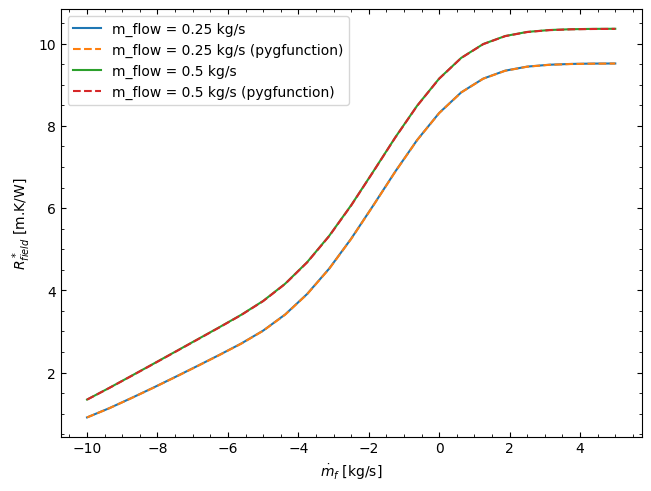

In [10]:
fig, ax = plt.subplots(constrained_layout=True)
ax = gt3.plot._format_axis(ax, [r'$\dot{m}_f$ [kg/s]', r'$R_{field}^*$ [m.K/W]'])
for _g_func, _g_func_pygfunction, _m_flow in zip(g_funcs, g_funcs_pygfunction, m_flow):
    ax.plot(tt_s, _g_func, label=f'm_flow = {_m_flow} kg/s')
    ax.plot(tt_s, _g_func_pygfunction.gFunc, label=f'm_flow = {_m_flow} kg/s (pygfunction)', linestyle='--')
# ax.set_ylim([0, 1.])
ax.legend()
plt.show()

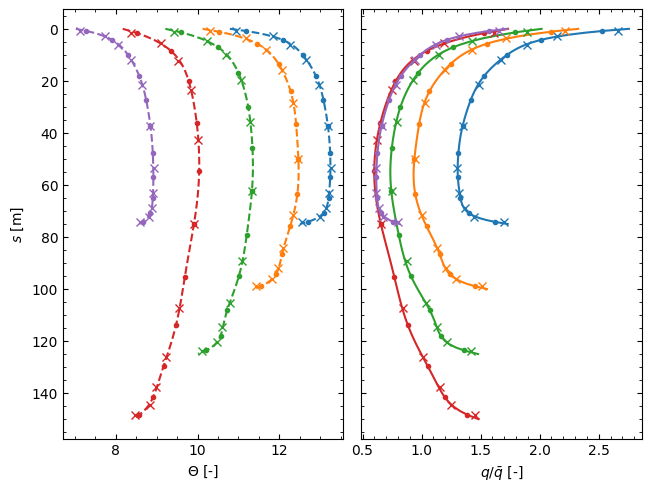

In [11]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Theta$ [-]', '$s$ [m]'], inverse_y=True)
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$q / \bar{q}$ [-]')
L_segment = g_funcs_pygfunction[0].solver.segment_lengths().reshape(n_boreholes, -1)
s_segments = np.cumulative_sum(L_segment, axis=1) - L_segment / 2
T_b_pygfunction = np.array(g_funcs_pygfunction[0]._temperature_profiles(None, np.arange(n_boreholes, dtype=int))[1]).reshape(n_boreholes, -1)
q_b_pygfunction = np.array(g_funcs_pygfunction[0]._heat_extraction_rate_profiles(None, np.arange(n_boreholes, dtype=int))[1]).reshape(n_boreholes, -1)
for i in range(field.n_boreholes):
    axs[0].plot(T_b_eval[i], s_eval[:, i], '--', color=f'C{i}')
    axs[0].plot(T_b_pygfunction[i], s_segments[i], 'x', color=f'C{i}')
    axs[0].plot(T_bs[0][-1][i], s_nodes[:, i], '.', color=f'C{i}')
    axs[1].plot(q_b_eval[i], s_eval[:, i], '-', color=f'C{i}')
    axs[1].plot(q_b_pygfunction[i], s_segments[i], 'x', color=f'C{i}')
    axs[1].plot(q_bs[0][-1][i], s_nodes[:, i], '.', color=f'C{i}')
plt.show()